##### Assignment 3 — Comparative Analysis of Learning Paradigms for Text Classification 
**Dataset:** `dair-ai/emotion` (6 emotions: joy, sadness, anger, fear, love, surprise)  
**Three paradigms:** From-Scratch RNN · Fine-Tuned BERT · LLM Prompting (Qwen2.5-3B-Instruct)
name:mariam ayman id 140044467
name: nouran ashraf id 13007718
name: nour ahmed id 13004694

## 0 · Setup & Installations

In [1]:
# Install all required libraries (run once on Kaggle)
!pip install -q datasets transformers bitsandbytes accelerate seaborn scikit-learn


In [2]:
# ── Core imports ──────────────────────────────────────────────────────────
import os, time, random, warnings, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter, defaultdict

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
)
from sklearn.metrics import (
    accuracy_score, f1_score,
    classification_report, confusion_matrix,
)

warnings.filterwarnings("ignore")

# ── Reproducibility ────────────────────────────────────────────────────────
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

SEED = 42
set_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device : {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU(s) : {[torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())]}")

LABEL_NAMES = ["sadness", "joy", "love", "anger", "fear", "surprise"]
NUM_CLASSES  = len(LABEL_NAMES)


Device : cuda
GPU(s) : ['Tesla T4', 'Tesla T4']


---
## Part 1 — Data Preprocessing & Exploration

In [3]:
# ── Load the dataset (split config → 16 000 / 2 000 / 2 000) ──────────────
dataset = load_dataset("dair-ai/emotion", "split")
print(dataset)


DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})


In [4]:
# ── Basic statistics per split ────────────────────────────────────────────
for split_name, split_data in dataset.items():
    labels = split_data["label"]
    counts = Counter(labels)
    print(f"\n=== {split_name.upper()} ({len(split_data)} examples) ===")
    for idx, name in enumerate(LABEL_NAMES):
        print(f"  {name:<10}: {counts[idx]:>5}  ({counts[idx]/len(split_data)*100:.1f}%)")



=== TRAIN (16000 examples) ===
  sadness   :  4666  (29.2%)
  joy       :  5362  (33.5%)
  love      :  1304  (8.2%)
  anger     :  2159  (13.5%)
  fear      :  1937  (12.1%)
  surprise  :   572  (3.6%)

=== VALIDATION (2000 examples) ===
  sadness   :   550  (27.5%)
  joy       :   704  (35.2%)
  love      :   178  (8.9%)
  anger     :   275  (13.8%)
  fear      :   212  (10.6%)
  surprise  :    81  (4.0%)

=== TEST (2000 examples) ===
  sadness   :   581  (29.0%)
  joy       :   695  (34.8%)
  love      :   159  (8.0%)
  anger     :   275  (13.8%)
  fear      :   224  (11.2%)
  surprise  :    66  (3.3%)


In [5]:
# ── Text-length statistics ────────────────────────────────────────────────
train_texts  = dataset["train"]["text"]
train_labels = dataset["train"]["label"]
lengths_chars  = [len(t) for t in train_texts]
lengths_words  = [len(t.split()) for t in train_texts]

print(f"Char  length — mean: {np.mean(lengths_chars):.1f}  median: {np.median(lengths_chars):.1f}  max: {max(lengths_chars)}")
print(f"Word  length — mean: {np.mean(lengths_words):.1f}  median: {np.median(lengths_words):.1f}  max: {max(lengths_words)}")


Char  length — mean: 96.8  median: 86.0  max: 300
Word  length — mean: 19.2  median: 17.0  max: 66


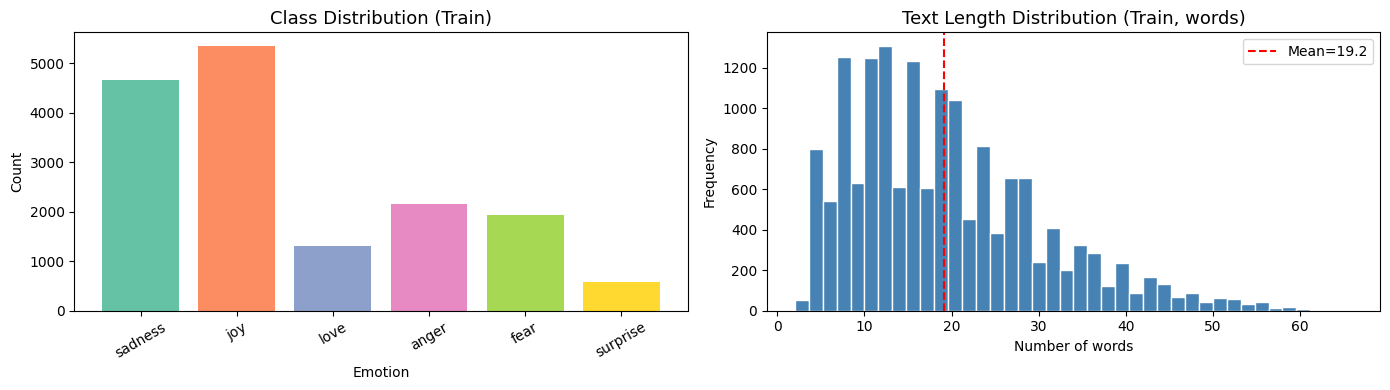

Figure saved.


In [6]:
# ── Visualisations: class balance + text length distribution ─────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Class balance bar chart
label_counts = Counter(train_labels)
axes[0].bar([LABEL_NAMES[i] for i in range(NUM_CLASSES)],
            [label_counts[i] for i in range(NUM_CLASSES)],
            color=plt.cm.Set2.colors)
axes[0].set_title("Class Distribution (Train)", fontsize=13)
axes[0].set_xlabel("Emotion")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis='x', rotation=30)

# Word length histogram
axes[1].hist(lengths_words, bins=40, color="steelblue", edgecolor="white")
axes[1].set_title("Text Length Distribution (Train, words)", fontsize=13)
axes[1].set_xlabel("Number of words")
axes[1].set_ylabel("Frequency")
axes[1].axvline(np.mean(lengths_words), color="red", linestyle="--", label=f"Mean={np.mean(lengths_words):.1f}")
axes[1].legend()

plt.tight_layout()
plt.savefig("part1_eda.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure saved.")


In [7]:
# ── Custom tokenizer / vocabulary for the from-scratch RNN ───────────────
# Lowercasing is applied; punctuation is kept (it carries emotional signal).
# Vocabulary is built only from the TRAINING set to avoid data leakage.

from collections import defaultdict

PAD_TOKEN, UNK_TOKEN = "<PAD>", "<UNK>"
MAX_SEQ_LEN = 60   # covers >95 % of samples (median ≈ 18 words)

def simple_tokenize(text):
    """Lower-case word tokenizer."""
    return text.lower().split()

def build_vocab(texts, min_freq=2):
    """Build vocabulary from a list of texts."""
    word_freq = defaultdict(int)

    for text in texts:
        for tok in simple_tokenize(text):
            word_freq[tok] += 1

    vocab = {PAD_TOKEN: 0, UNK_TOKEN: 1}

    for word, freq in sorted(word_freq.items(), key=lambda x: -x[1]):
        if freq >= min_freq:
            vocab[word] = len(vocab)

    return vocab

vocab = build_vocab(dataset["train"]["text"], min_freq=2)

VOCAB_SIZE = len(vocab)
print(f"Vocabulary size : {VOCAB_SIZE:,}  (min_freq=2, max_seq_len={MAX_SEQ_LEN})")

def encode_rnn(text, vocab, max_len=MAX_SEQ_LEN):
    """Convert a text string to a padded list of token indices."""
    tokens = simple_tokenize(text)[:max_len]
    ids = [vocab.get(t, vocab[UNK_TOKEN]) for t in tokens]
    ids += [vocab[PAD_TOKEN]] * (max_len - len(ids))
    return ids

Vocabulary size : 7,401  (min_freq=2, max_seq_len=60)


In [8]:

# ── Pretrained tokenizer for BERT (Parts 3 & 4) ─────────────────────────
# AutoTokenizer handles sub-word tokenisation, lowercasing,
# [CLS]/[SEP] insertion, and attention masks automatically.
# No manual cleaning needed — bert-base-uncased lowercases all input internally.

BERT_MODEL_NAME = "bert-base-uncased"
bert_tokenizer  = AutoTokenizer.from_pretrained(BERT_MODEL_NAME)

# Quick sanity check
sample = dataset["train"][0]
enc = bert_tokenizer(sample["text"], truncation=True, max_length=128)
print(f"Sample text    : {sample['text']}")
print(f"Label          : {LABEL_NAMES[sample['label']]}")
print(f"Token ids      : {enc['input_ids'][:10]} ...")
print(f"Decoded tokens : {bert_tokenizer.convert_ids_to_tokens(enc['input_ids'][:10])} ...")


Sample text    : i didnt feel humiliated
Label          : sadness
Token ids      : [101, 1045, 2134, 2102, 2514, 26608, 102] ...
Decoded tokens : ['[CLS]', 'i', 'didn', '##t', 'feel', 'humiliated', '[SEP]'] ...


### Preprocessing Justification

| Choice | Decision | Reason |
|--------|----------|--------|
| Lowercasing for RNN | Applied | The custom RNN vocabulary uses lowercase tokens to reduce vocabulary size and avoid treating words such as `Happy` and `happy` as different tokens. |
| Punctuation removal | Not applied | The tokenizer uses simple whitespace splitting, so punctuation is kept because symbols such as `!`, `...`, or `?` may carry emotional intensity. |
| RNN maximum sequence length | 60 tokens | The training texts are short, with an average of about 19 words and a maximum of 66 words, so 60 tokens covers almost all samples while limiting padding. |
| Minimum token frequency | 2 | Rare words appearing only once are removed to reduce noise and vocabulary size. Unknown rare words are mapped to `<UNK>`. |
| BERT tokenizer | No manual cleaning | `bert-base-uncased` handles lowercasing, WordPiece subword tokenization, special tokens, truncation, and attention masks automatically. |

---
## Part 2 — Baseline: From-Scratch LSTM Classifier

In [9]:
# ── PyTorch Dataset for the RNN ───────────────────────────────────────────
class EmotionRNNDataset(Dataset):
    def __init__(self, hf_split, vocab, max_len=MAX_SEQ_LEN):
        self.encodings = [encode_rnn(t, vocab, max_len) for t in hf_split["text"]]
        self.labels    = hf_split["label"]

    def __len__(self):  return len(self.labels)

    def __getitem__(self, idx):
        return (torch.tensor(self.encodings[idx], dtype=torch.long),
                torch.tensor(self.labels[idx],    dtype=torch.long))

rnn_train_ds = EmotionRNNDataset(dataset["train"],      vocab)
rnn_val_ds   = EmotionRNNDataset(dataset["validation"], vocab)
rnn_test_ds  = EmotionRNNDataset(dataset["test"],       vocab)

BATCH_SIZE = 64
rnn_train_loader = DataLoader(rnn_train_ds, batch_size=BATCH_SIZE, shuffle=True)
rnn_val_loader   = DataLoader(rnn_val_ds,  batch_size=BATCH_SIZE)
rnn_test_loader  = DataLoader(rnn_test_ds, batch_size=BATCH_SIZE)
print(f"Train batches: {len(rnn_train_loader)} | Val batches: {len(rnn_val_loader)} | Test batches: {len(rnn_test_loader)}")


Train batches: 250 | Val batches: 32 | Test batches: 32


In [10]:
# ── LSTM Classifier architecture ──────────────────────────────────────────
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_layers, num_classes, dropout=0.4):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm      = nn.LSTM(embed_dim, hidden_dim, num_layers=num_layers,
                                  batch_first=True, dropout=dropout if num_layers > 1 else 0,
                                  bidirectional=True)
        self.dropout   = nn.Dropout(dropout)
        self.fc        = nn.Linear(hidden_dim * 2, num_classes)  # *2 for bidirectional

    def forward(self, x):
        emb  = self.dropout(self.embedding(x))          # (B, T, E)
        out, (hn, _) = self.lstm(emb)                   # out: (B, T, 2H)
        # Concatenate last hidden state from both directions
        hn   = torch.cat([hn[-2], hn[-1]], dim=1)       # (B, 2H)
        return self.fc(self.dropout(hn))                 # (B, C)

EMBED_DIM  = 128
HIDDEN_DIM = 256
NUM_LAYERS = 2

rnn_model = LSTMClassifier(VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, NUM_LAYERS, NUM_CLASSES).to(DEVICE)
total_params = sum(p.numel() for p in rnn_model.parameters() if p.requires_grad)
print(f"LSTM trainable parameters: {total_params:,}")
print(rnn_model)


LSTM trainable parameters: 3,317,894
LSTMClassifier(
  (embedding): Embedding(7401, 128, padding_idx=0)
  (lstm): LSTM(128, 256, num_layers=2, batch_first=True, dropout=0.4, bidirectional=True)
  (dropout): Dropout(p=0.4, inplace=False)
  (fc): Linear(in_features=512, out_features=6, bias=True)
)


In [11]:
# ── Training the LSTM with Early Stopping + Best Epoch Selection ──────────
import copy
import time
import torch
import torch.nn as nn

EPOCHS_RNN = 20
LR_RNN = 1e-3

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(rnn_model.parameters(), lr=LR_RNN)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    patience=2,
    factor=0.5,
    min_lr=1e-5
)

early_stop_patience = 4
best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0
best_model_state = None

rnn_train_losses, rnn_val_losses = [], []
rnn_train_accs, rnn_val_accs = [], []

rnn_train_start = time.time()

for epoch in range(1, EPOCHS_RNN + 1):

    # ── Train ──
    rnn_model.train()
    running_loss, correct, total = 0.0, 0, 0

    for xb, yb in rnn_train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)

        optimizer.zero_grad()
        logits = rnn_model(xb)
        loss = criterion(logits, yb)

        loss.backward()
        nn.utils.clip_grad_norm_(rnn_model.parameters(), 1.0)
        optimizer.step()

        running_loss += loss.item() * xb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += xb.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # ── Validate ──
    rnn_model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for xb, yb in rnn_val_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)

            logits = rnn_model(xb)
            loss = criterion(logits, yb)

            val_loss += loss.item() * xb.size(0)
            val_correct += (logits.argmax(1) == yb).sum().item()
            val_total += xb.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    # save history
    rnn_train_losses.append(train_loss)
    rnn_val_losses.append(val_loss)
    rnn_train_accs.append(train_acc)
    rnn_val_accs.append(val_acc)

    # reduce LR when validation loss stops improving
    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    print(f"Epoch {epoch:02d}/{EPOCHS_RNN}  "
          f"train_loss={train_loss:.4f}  train_acc={train_acc:.4f}  "
          f"val_loss={val_loss:.4f}  val_acc={val_acc:.4f}  "
          f"lr={current_lr:.6f}")

    # ── Best model checkpoint ──
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        best_model_state = copy.deepcopy(rnn_model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    # ── Early stopping ──
    if epochs_without_improvement >= early_stop_patience:
        print(f"\nEarly stopping triggered at epoch {epoch}.")
        print(f"Best epoch was {best_epoch} with val_loss={best_val_loss:.4f}.")
        break

# restore best model
rnn_model.load_state_dict(best_model_state)

rnn_train_time = time.time() - rnn_train_start

print(f"\nBest RNN model restored from epoch {best_epoch}.")
print(f"Total RNN training time: {rnn_train_time:.1f}s ({rnn_train_time/60:.2f} min)")

Epoch 01/20  train_loss=1.5299  train_acc=0.3887  val_loss=1.3390  val_acc=0.4995  lr=0.001000
Epoch 02/20  train_loss=1.1980  train_acc=0.5678  val_loss=0.8286  val_acc=0.7125  lr=0.001000
Epoch 03/20  train_loss=0.8088  train_acc=0.7211  val_loss=0.4783  val_acc=0.8365  lr=0.001000
Epoch 04/20  train_loss=0.5474  train_acc=0.8093  val_loss=0.3142  val_acc=0.8895  lr=0.001000
Epoch 05/20  train_loss=0.3929  train_acc=0.8589  val_loss=0.2215  val_acc=0.9150  lr=0.001000
Epoch 06/20  train_loss=0.2911  train_acc=0.8916  val_loss=0.1764  val_acc=0.9230  lr=0.001000
Epoch 07/20  train_loss=0.2327  train_acc=0.9098  val_loss=0.1598  val_acc=0.9250  lr=0.001000
Epoch 08/20  train_loss=0.1988  train_acc=0.9218  val_loss=0.1654  val_acc=0.9235  lr=0.001000
Epoch 09/20  train_loss=0.1704  train_acc=0.9283  val_loss=0.1464  val_acc=0.9340  lr=0.001000
Epoch 10/20  train_loss=0.1560  train_acc=0.9323  val_loss=0.1477  val_acc=0.9285  lr=0.001000
Epoch 11/20  train_loss=0.1414  train_acc=0.9369  

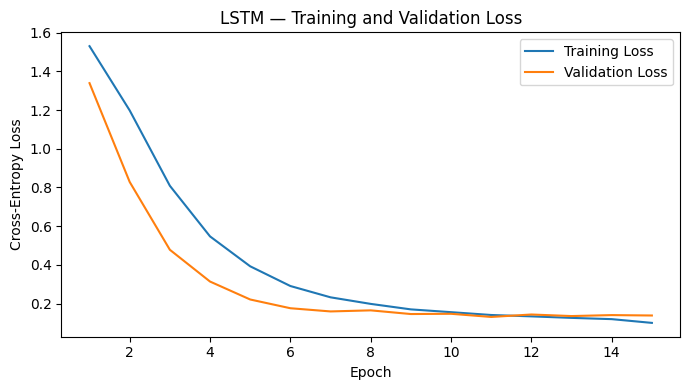

In [12]:
# ── Loss curves across epochs ─────────────────────────────────────────────
plt.figure(figsize=(7, 4))

epochs_range = range(1, len(rnn_train_losses) + 1)

plt.plot(epochs_range, rnn_train_losses, label="Training Loss")
plt.plot(epochs_range, rnn_val_losses, label="Validation Loss")

plt.title("LSTM — Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.legend()

plt.tight_layout()
plt.savefig("part2_lstm_loss_curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
# ── Evaluation helpers ────────────────────────────────────────────────────
def evaluate_model_rnn(model, loader, device=DEVICE):
    model.eval()
    all_preds, all_labels = [], []
    start = time.time()

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            preds = model(xb).argmax(1).cpu().tolist()
            all_preds.extend(preds)
            all_labels.extend(yb.tolist())

    inference_time = time.time() - start
    return all_labels, all_preds, inference_time


def print_metrics(y_true, y_pred, label_names, infer_time, title):
    acc = accuracy_score(y_true, y_pred)

    # Macro F1 over the real 6 emotion classes only.
    # Unknown predictions still count as wrong, but are not treated as a 7th class.
    f1 = f1_score(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        average="macro",
        zero_division=0
    )

    print(f"\n{title}")
    print(f"Accuracy: {acc:.4f}")
    print(f"Macro F1: {f1:.4f}")
    print(f"Inference time: {infer_time:.2f}s")

    print(classification_report(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=LABEL_NAMES,
        zero_division=0
    ))

    return acc, f1


def plot_confusion(labels, preds, label_names, title):
    # Force the confusion matrix to include all provided labels.
    # This is important for LLM unknown outputs.
    cm = confusion_matrix(
        labels,
        preds,
        labels=list(range(len(label_names)))
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=label_names,
        yticklabels=label_names
    )

    plt.title(title, fontsize=13)
    plt.ylabel("True label")
    plt.xlabel("Predicted label")
    plt.tight_layout()
    plt.savefig(f"{title.replace(' ', '_').lower()}.png", dpi=150, bbox_inches="tight")
    plt.show()


Part 2 — LSTM (full data)
Accuracy: 0.9285
Macro F1: 0.8796
Inference time: 0.49s
              precision    recall  f1-score   support

     sadness       0.97      0.97      0.97       581
         joy       0.92      0.98      0.94       695
        love       0.92      0.74      0.82       159
       anger       0.96      0.91      0.93       275
        fear       0.86      0.93      0.89       224
    surprise       0.85      0.62      0.72        66

    accuracy                           0.93      2000
   macro avg       0.91      0.86      0.88      2000
weighted avg       0.93      0.93      0.93      2000



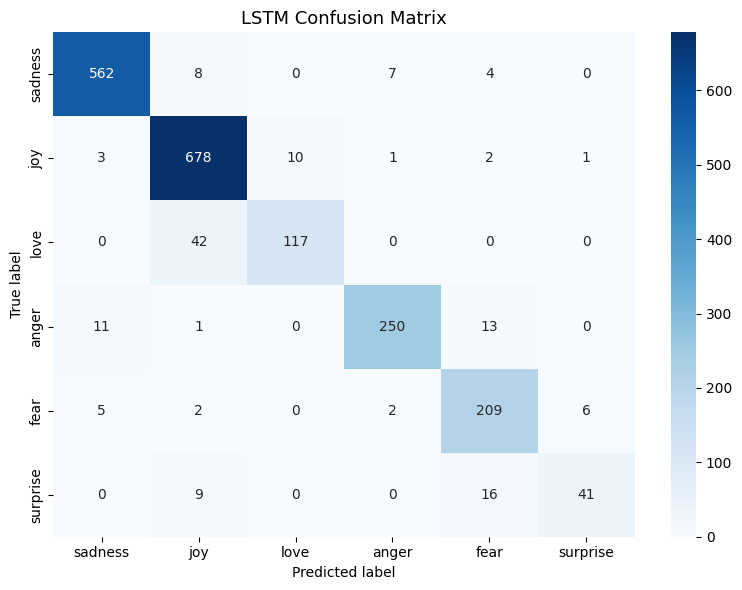

Training time : 130.3s | Inference time: 0.49s


In [14]:
# ── Test-set evaluation for LSTM ─────────────────────────────────────────
rnn_labels, rnn_preds, rnn_infer_time = evaluate_model_rnn(rnn_model, rnn_test_loader)
rnn_acc, rnn_f1 = print_metrics(rnn_labels, rnn_preds, LABEL_NAMES, rnn_infer_time, "Part 2 — LSTM (full data)")
plot_confusion(rnn_labels, rnn_preds, LABEL_NAMES, "LSTM Confusion Matrix")
print(f"Training time : {rnn_train_time:.1f}s | Inference time: {rnn_infer_time:.2f}s")


### Part 2 — LSTM Results & Discussion

**Architecture:** Bidirectional 2-layer LSTM with a 128-dim embedding layer, 256 hidden units per direction, and 0.4 dropout. Total trainable parameters: **3,317,894**.

**Training:** The model was trained with Adam (lr=1e-3), cross-entropy loss, gradient clipping at 1.0, and `ReduceLROnPlateau` scheduling. Early stopping (patience=4) triggered at epoch 15; the best checkpoint was restored from **epoch 11** with a validation loss of **0.1314**. Total training time: **130.3 s (2.17 min)**.

**Test-set performance:**

| Metric | Value |
|--------|-------|
| Accuracy | **0.9285** |
| Macro F1 | **0.8796** |
| Inference time | 0.49 s |

**Per-class breakdown:**

| Class | Precision | Recall | F1 | Support |
|-------|-----------|--------|----|---------|
| sadness | 0.97 | 0.97 | 0.97 | 581 |
| joy | 0.92 | 0.98 | 0.94 | 695 |
| love | 0.92 | 0.74 | 0.82 | 159 |
| anger | 0.96 | 0.91 | 0.93 | 275 |
| fear | 0.86 | 0.93 | 0.89 | 224 |
| surprise | 0.85 | 0.62 | 0.72 | 66 |

**Discussion:** The LSTM achieves strong overall accuracy of 92.85% despite learning all representations from scratch on only 16,000 examples. High-frequency classes (*sadness*, *joy*) are classified almost perfectly. The two weakest classes are *surprise* (F1 = 0.72, recall = 0.62) and *love* (F1 = 0.82, recall = 0.74) — both are minority classes with low support, making them harder to learn. *Surprise* in particular has only 66 test examples (3.3% of the test set), so the model has seen very few examples during training. Bidirectionality and the two-layer depth are important contributors: the model can capture both forward and backward context, which helps distinguish subtle emotional cues in short texts.


---
## Part 3 — Transfer Learning: Fine-Tuned BERT

In [15]:
# ── Tokenise the dataset for BERT ──────────────────────────────────
BERT_MAX_LEN = 128   # covers all tweets; saves memory vs 512

def tokenize_bert(batch):
    return bert_tokenizer(batch["text"], truncation=True, max_length=BERT_MAX_LEN)

tokenized_ds = dataset.map(tokenize_bert, batched=True)
tokenized_ds = tokenized_ds.rename_column("label", "labels")
tokenized_ds.set_format("torch", columns=["input_ids", "attention_mask", "labels"])
print(tokenized_ds)


DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2000
    })
})


In [16]:
# ── Load BERT with a classification head ───────────────────────────
bert_model = AutoModelForSequenceClassification.from_pretrained(
    BERT_MODEL_NAME,
    num_labels=NUM_CLASSES,
    id2label={i: l for i, l in enumerate(LABEL_NAMES)},
    label2id={l: i for i, l in enumerate(LABEL_NAMES)},
)
bert_model = bert_model.to(DEVICE)

bert_params = sum(p.numel() for p in bert_model.parameters() if p.requires_grad)
print(f"BERT total trainable parameters : {bert_params:,}")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT total trainable parameters : 109,486,854


In [17]:
# ── Compute-metrics callback for Trainer ─────────────────────────────────
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "macro_f1": f1_score(labels, preds, average="macro"),
    }


In [18]:
# ── Training arguments ────────────────────────────────────────────────────
bert_train_start = time.time()

training_args = TrainingArguments(
    output_dir="./bert_output",
    num_train_epochs=3,
    per_device_train_batch_size=16,   # safer for BERT
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    warmup_ratio=0.1,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model = "eval_loss",
    greater_is_better = False,
    logging_steps=50,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42,
)
data_collator = DataCollatorWithPadding(tokenizer=bert_tokenizer)

trainer = Trainer(
    model           = bert_model,
    args            = training_args,
    train_dataset   = tokenized_ds["train"],
    eval_dataset    = tokenized_ds["validation"],
    compute_metrics = compute_metrics,
    data_collator   = data_collator,
)

trainer.train()
bert_train_time = time.time() - bert_train_start
print(f"\nBERT training time: {bert_train_time:.1f}s ({bert_train_time/60:.2f} min)")


warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.481733,0.449890,0.924500,0.902899
2,0.253351,0.319959,0.942000,0.920587
3,0.189979,0.301647,0.938500,0.913596


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La


BERT training time: 411.8s (6.86 min)


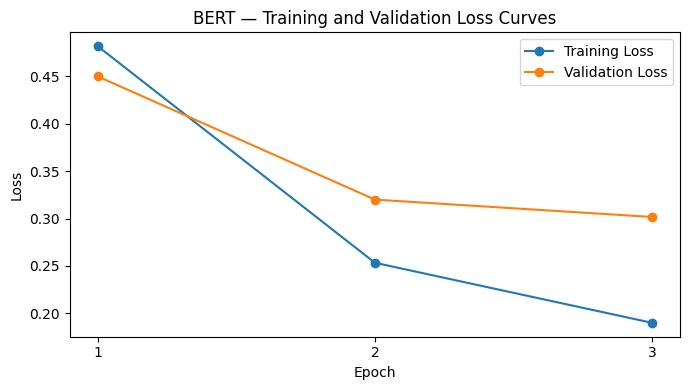

In [19]:
# ── BERT loss curves from Trainer logs ───────────────────────────────
log_history = trainer.state.log_history

# Get only epoch-level evaluation rows
eval_logs = [log for log in log_history if "eval_loss" in log]

epochs = [log["epoch"] for log in eval_logs]
val_losses = [log["eval_loss"] for log in eval_logs]

# Get training loss closest to each evaluation epoch
train_losses = []

for epoch in epochs:
    train_logs_before_epoch = [
        log for log in log_history
        if "loss" in log and "eval_loss" not in log and "epoch" in log and log["epoch"] <= epoch
    ]
    train_losses.append(train_logs_before_epoch[-1]["loss"])

plt.figure(figsize=(7, 4))
plt.plot(epochs, train_losses, marker="o", label="Training Loss")
plt.plot(epochs, val_losses, marker="o", label="Validation Loss")

plt.title("BERT — Training and Validation Loss Curves")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.tight_layout()
plt.show()


Part 3 — BERT (full data)
Accuracy: 0.9275
Macro F1: 0.8862
Inference time: 4.63s
              precision    recall  f1-score   support

     sadness       0.96      0.96      0.96       581
         joy       0.95      0.95      0.95       695
        love       0.86      0.82      0.84       159
       anger       0.92      0.90      0.91       275
        fear       0.86      0.93      0.90       224
    surprise       0.84      0.70      0.76        66

    accuracy                           0.93      2000
   macro avg       0.90      0.88      0.89      2000
weighted avg       0.93      0.93      0.93      2000



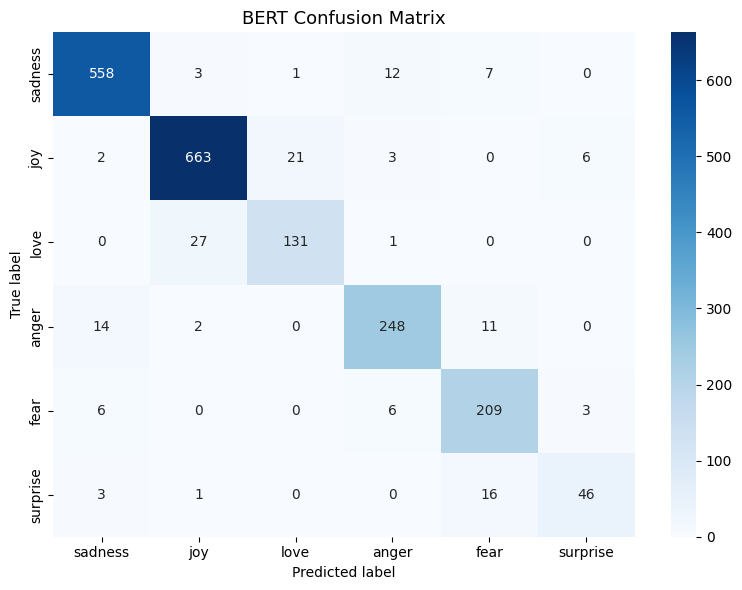

Training time : 411.8s | Inference time: 4.63s


In [20]:
# ── Evaluate BERT on test set ──────────────────────────────────────
infer_start = time.time()
bert_preds_out = trainer.predict(tokenized_ds["test"])
bert_infer_time = time.time() - infer_start

bert_preds  = np.argmax(bert_preds_out.predictions, axis=1)
bert_labels = bert_preds_out.label_ids

bert_acc, bert_f1 = print_metrics(
    bert_labels.tolist(), bert_preds.tolist(),
    LABEL_NAMES, bert_infer_time, "Part 3 — BERT (full data)"
)
plot_confusion(bert_labels.tolist(), bert_preds.tolist(), LABEL_NAMES, "BERT Confusion Matrix")
print(f"Training time : {bert_train_time:.1f}s | Inference time: {bert_infer_time:.2f}s")


**Architecture:**  Qwen2.5-3B-Instruct is a 3-billion-parameter instruction-tuned, decoder-only Transformer language model. It is built for causal text generation, meaning it predicts the next token based on the previous context. Because it has been instruction-tuned, it can follow natural-language prompts and produce task-specific outputs, such as classifying a text into one of the six emotion labels.

**Pretraining objective:** The model is pretrained using **Causal Language Modeling (CLM)**, where it predicts the next token from previous tokens. It is then instruction-tuned so it can better follow natural-language prompts.

**Why Qwen2.5-3B:** The assignment allows any open instruction-tuned LLM that fits in memory. Qwen2.5-3B-Instruct is small enough to run with 4-bit quantization on Kaggle GPUs while still providing useful prompt-following ability for zero-shot, few-shot, and chain-of-thought emotion classification.

**Important note:** Unlike the LSTM and BERT models, this model is not trained or fine-tuned in this notebook. It is only prompted, so its cost is inference time rather than training time.

### Part 3 — BERT Results & Discussion

**Test-set performance:**

| Metric | Value |
|--------|-------|
| Accuracy | **0.9275** |
| Macro F1 | **0.8862** |
| Training time | 411.8 s (6.86 min) |
| Inference time | 4.63 s |

**Per-class breakdown:**

| Class | Precision | Recall | F1 | Support |
|-------|-----------|--------|----|---------|
| sadness | 0.96 | 0.96 | 0.96 | 581 |
| joy | 0.95 | 0.95 | 0.95 | 695 |
| love | 0.86 | 0.82 | 0.84 | 159 |
| anger | 0.92 | 0.90 | 0.91 | 275 |
| fear | 0.86 | 0.93 | 0.90 | 224 |
| surprise | 0.84 | 0.70 | 0.76 | 66 |

**Discussion:** BERT's raw accuracy (0.9275) is marginally below the LSTM (0.9285), but it achieves a higher **Macro F1 of 0.8862 vs 0.8796** — meaning it is more balanced across all six classes, particularly on minority classes. The LSTM had a precision advantage on *love* (0.92 vs 0.86), but BERT improves recall for *love* (0.82 vs 0.74), leading to a better F1. BERT also improves *joy* precision (0.95 vs 0.92). The weakest classes remain *surprise* and *love*, but the gaps are smaller than with the LSTM, confirming that pretrained contextual representations generalize better to low-frequency emotional categories. The cost of this improvement is training time: BERT takes 411.8 s vs the LSTM's 130.3 s, and inference is ~9× slower per batch (4.63 s vs 0.49 s) due to the attention mechanism over the full sequence.


---
## Part 4 — LLM Prompting (No Training)
### Model: `Qwen/Qwen2.5-3B-Instruct`

**Architecture:** Qwen2.5-3B-Instruct is a 3B-parameter decoder-only transformer instruction model.

**Pretraining objective:** The model is pretrained using **Causal Language Modeling (CLM)**, where it predicts the next token from previous tokens. It is then instruction-tuned so it can better follow natural-language prompts.

**Why Qwen2.5-3B:** The assignment allows any open instruction-tuned LLM that fits in memory. Qwen2.5-3B-Instruct is small enough to run with 4-bit quantization on Kaggle GPUs while still providing useful prompt-following ability for zero-shot, few-shot, and chain-of-thought emotion classification.

**Important note:** Unlike the LSTM and BERT models, this model is not trained or fine-tuned in this notebook. It is only prompted, so its cost is inference time rather than training time.

In [21]:
# ── Load Qwen2.5-3B-Instruct with 4-bit quantisation ─────────────────────

LLM_MODEL = "Qwen/Qwen2.5-3B-Instruct"

bnb_config = BitsAndBytesConfig(
    load_in_4bit              = True,
    bnb_4bit_quant_type       = "nf4",
    bnb_4bit_compute_dtype    = torch.float16,
    bnb_4bit_use_double_quant = True,
)

llm_tokenizer = AutoTokenizer.from_pretrained(
    LLM_MODEL,
    trust_remote_code=True
)

if llm_tokenizer.pad_token is None:
    llm_tokenizer.pad_token = llm_tokenizer.eos_token

llm_model = AutoModelForCausalLM.from_pretrained(
    LLM_MODEL,
    quantization_config = bnb_config,
    device_map          = "auto",
    torch_dtype         = torch.float16,
    trust_remote_code   = True,
)

llm_model.eval()
print("Qwen2.5-3B-Instruct loaded successfully.")

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen2.5-3B-Instruct loaded successfully.


In [22]:
# ── Generation helper for Qwen2.5 ────────────────────────────────────
# Qwen2.5 uses a standard chat template via apply_chat_template()

VALID_LABELS = set(LABEL_NAMES)

def llm_generate(prompt: str, max_new_tokens: int = 30) -> str:
    """Run a prompt through Qwen2.5 and return only the newly generated text."""
    messages  = [{"role": "user", "content": prompt}]
    formatted = llm_tokenizer.apply_chat_template(
        messages,
        tokenize              = False,
        add_generation_prompt = True,
    )
    inputs = llm_tokenizer(formatted, return_tensors="pt").to(llm_model.device)

    with torch.no_grad():
        output_ids = llm_model.generate(
            **inputs,
            max_new_tokens = max_new_tokens,
            do_sample      = False,   # greedy — most reliable for classification
            pad_token_id   = llm_tokenizer.eos_token_id,
        )

    # Decode only the newly generated tokens (exclude the prompt)
    new_ids = output_ids[0, inputs["input_ids"].shape[1]:]
    return llm_tokenizer.decode(new_ids, skip_special_tokens=True).strip()


def parse_label(raw_output: str) -> str:
    """Extract the first valid emotion label from the model's raw output.
    Uses word-boundary regex so 'fearless' cannot match 'fear', etc.
    Returns whichever valid label appears earliest in the output.
    """
    import re
    raw_lower = raw_output.lower()
    first_pos, first_label = len(raw_lower) + 1, "unknown"
    for label in LABEL_NAMES:
        m = re.search(r'\b' + re.escape(label) + r'\b', raw_lower)
        if m and m.start() < first_pos:
            first_pos, first_label = m.start(), label
    return first_label


def run_llm_eval(prompt_fn, split, sample_size=None, setting_name="LLM",
                 parse_fn=parse_label, max_new_tokens=40, progress_every=100):

    if sample_size is None or sample_size >= len(split):
        indices = list(range(len(split)))
    else:
        rng = random.Random(SEED)
        indices = rng.sample(range(len(split)), sample_size)

    y_true, y_pred = [], []
    start_time = time.time()

    print(f"\nStarting {setting_name} evaluation on {len(indices)} examples...")

    for step, idx in enumerate(indices, start=1):
        text = split["text"][idx]
        true_label = split["label"][idx]

        prompt = prompt_fn(text)
        raw_output = llm_generate(prompt, max_new_tokens=max_new_tokens)
        pred_label = parse_fn(raw_output)
        pred_int = LABEL_NAMES.index(pred_label) if pred_label in LABEL_NAMES else -1

        y_true.append(true_label)
        y_pred.append(pred_int)

        if step % progress_every == 0 or step == len(indices):
            preds_for_metrics = [p if p != -1 else NUM_CLASSES for p in y_pred]
            current_acc = accuracy_score(y_true, preds_for_metrics)
            current_f1 = f1_score(
                y_true,
                preds_for_metrics,
                labels=list(range(NUM_CLASSES)),
                average="macro",
                zero_division=0
            )
            unknowns = sum(1 for p in y_pred if p == -1)
            elapsed = time.time() - start_time

            print(
                f"{setting_name}: {step}/{len(indices)} done | "
                f"Acc={current_acc:.4f} | Macro F1={current_f1:.4f} | "
                f"Unknown={unknowns} | Time={elapsed:.1f}s"
            )

    infer_time = time.time() - start_time
    print(f"\n{setting_name} evaluation finished in {infer_time:.2f}s")

    return y_true, y_pred, infer_time


LLM_EVAL_SIZE = 2000   # full test set
print(f"Evaluation sample size: {LLM_EVAL_SIZE} examples per setting.")


Evaluation sample size: 2000 examples per setting.


In [23]:
def show_llm_examples(prompt_fn, title, n=3, parse_fn=parse_label, max_new_tokens=40):
    print(f"=== {title} ===")

    for i in range(n):
        text = dataset["test"]["text"][i]
        true = LABEL_NAMES[dataset["test"]["label"][i]]

        prompt = prompt_fn(text)
        raw = llm_generate(prompt, max_new_tokens=max_new_tokens)
        pred = parse_fn(raw)

        print("\n" + "=" * 80)
        print(f"Example {i+1}")
        print("=" * 80)
        print("FULL PROMPT:\n")
        print(prompt)
        print("\nTRUE LABEL:", true)
        print("\nRAW MODEL OUTPUT:\n")
        print(raw)
        print("\nPARSED LABEL:", pred)

In [24]:
# ── ZERO-SHOT prompting ───────────────────────────────────────────────────
def zero_shot_prompt(text):
    return (
        "You are an emotion classifier. "
        "Classify the following text into exactly one of these emotions: "
        "joy, sadness, anger, fear, love, surprise.\n"
        "Respond with the emotion label only — no explanation.\n\n"
        f"Text: {text}\n"
        "Emotion:"
    )

# Show 3 example prompts and raw outputs before full evaluation
show_llm_examples(zero_shot_prompt, "Zero-Shot Example Prompts", n=3)

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


=== Zero-Shot Example Prompts ===

Example 1
FULL PROMPT:

You are an emotion classifier. Classify the following text into exactly one of these emotions: joy, sadness, anger, fear, love, surprise.
Respond with the emotion label only — no explanation.

Text: im feeling rather rotten so im not very ambitious right now
Emotion:

TRUE LABEL: sadness

RAW MODEL OUTPUT:

sadness

PARSED LABEL: sadness

Example 2
FULL PROMPT:

You are an emotion classifier. Classify the following text into exactly one of these emotions: joy, sadness, anger, fear, love, surprise.
Respond with the emotion label only — no explanation.

Text: im updating my blog because i feel shitty
Emotion:

TRUE LABEL: sadness

RAW MODEL OUTPUT:

Sadness

PARSED LABEL: sadness

Example 3
FULL PROMPT:

You are an emotion classifier. Classify the following text into exactly one of these emotions: joy, sadness, anger, fear, love, surprise.
Respond with the emotion label only — no explanation.

Text: i never make her separate from


Running zero-shot evaluation...

Starting Zero-shot evaluation on 2000 examples...
Zero-shot: 100/2000 done | Acc=0.6300 | Macro F1=0.5756 | Unknown=3 | Time=29.1s
Zero-shot: 200/2000 done | Acc=0.5800 | Macro F1=0.4896 | Unknown=6 | Time=57.9s
Zero-shot: 300/2000 done | Acc=0.5667 | Macro F1=0.4574 | Unknown=7 | Time=86.6s
Zero-shot: 400/2000 done | Acc=0.5400 | Macro F1=0.4378 | Unknown=8 | Time=115.5s
Zero-shot: 500/2000 done | Acc=0.5520 | Macro F1=0.4414 | Unknown=10 | Time=143.7s
Zero-shot: 600/2000 done | Acc=0.5400 | Macro F1=0.4360 | Unknown=15 | Time=172.1s
Zero-shot: 700/2000 done | Acc=0.5314 | Macro F1=0.4288 | Unknown=18 | Time=200.4s
Zero-shot: 800/2000 done | Acc=0.5400 | Macro F1=0.4276 | Unknown=19 | Time=228.3s
Zero-shot: 900/2000 done | Acc=0.5478 | Macro F1=0.4332 | Unknown=19 | Time=256.4s
Zero-shot: 1000/2000 done | Acc=0.5540 | Macro F1=0.4413 | Unknown=21 | Time=284.3s
Zero-shot: 1100/2000 done | Acc=0.5555 | Macro F1=0.4476 | Unknown=23 | Time=311.9s
Zero-sho

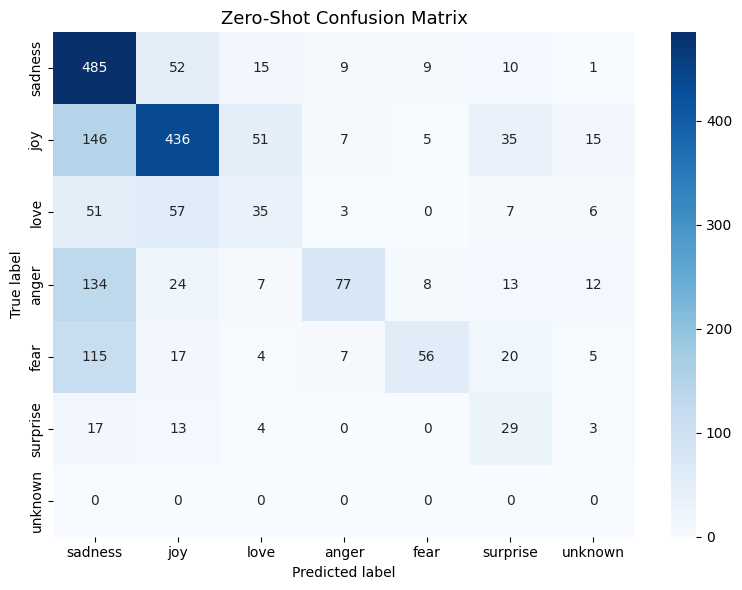

Unparseable outputs counted as wrong: 42/2000


In [25]:
# Full zero-shot evaluation
print("\nRunning zero-shot evaluation...")

zs_labels, zs_preds, zs_time = run_llm_eval(
    zero_shot_prompt,
    dataset["test"],
    sample_size=LLM_EVAL_SIZE,
    setting_name="Zero-shot"
)

# Unparseable outputs → counted as wrong
zs_preds_for_metrics = [p if p != -1 else NUM_CLASSES for p in zs_preds]
n_unknown_zs = sum(1 for p in zs_preds if p == -1)

zs_acc, zs_f1 = print_metrics(
    zs_labels,
    zs_preds_for_metrics,
    LABEL_NAMES,
    zs_time,
    "Part 4 — Zero-Shot"
)

# Confusion matrix includes unknown predictions instead of hiding them
plot_confusion(
    zs_labels,
    zs_preds_for_metrics,
    LABEL_NAMES + ["unknown"],
    "Zero-Shot Confusion Matrix"
)

print(f"Unparseable outputs counted as wrong: {n_unknown_zs}/{len(zs_preds)}")

In [26]:

# ── Balanced few-shot prompt builder ──────────────────────────────────────
def few_shot_prompt(k):
    """
    Builds a few-shot prompt with exactly k labeled examples.
    Examples are selected as evenly as possible across the six classes.
    Uses local RNG to avoid changing global randomness.
    """

    rng = random.Random(SEED)

    train_by_class = {i: [] for i in range(NUM_CLASSES)}
    for i in range(len(dataset["train"])):
        train_by_class[dataset["train"]["label"][i]].append(dataset["train"]["text"][i])

    base = k // NUM_CLASSES
    remainder = k % NUM_CLASSES

    examples = []

    for label_idx in range(NUM_CLASSES):
        n = base + (1 if label_idx < remainder else 0)
        chosen = rng.sample(train_by_class[label_idx], n)

        for text in chosen:
            examples.append(f'Text: "{text}"\nEmotion: {LABEL_NAMES[label_idx]}')

    rng.shuffle(examples)
    examples_block = "\n\n".join(examples)

    def prompt_fn(text):
        return f"""You are an emotion classifier.
Classify the following text into exactly one of these emotions:
{", ".join(LABEL_NAMES)}.

Here are labeled examples:

{examples_block}

Now classify this text. Respond with the label only.
Text: {text}
Emotion:"""

    return prompt_fn

fs3_fn = few_shot_prompt(3)


# Show 3 examples for few-shot (3)
show_llm_examples(fs3_fn, "Few-Shot (3) Example Prompts", n=3)

=== Few-Shot (3) Example Prompts ===

Example 1
FULL PROMPT:

You are an emotion classifier.
Classify the following text into exactly one of these emotions:
sadness, joy, love, anger, fear, surprise.

Here are labeled examples:

Text: "i have been feeling conflicted on whether or not i as a follower of christ should celebrate the ever popular pagan originated modern day holidays"
Emotion: joy

Text: "ive been feeling a bit nostalgic ever since i went through a box of my dads old pictures for a post i did for a href http mysalvagedtreasures"
Emotion: love

Text: "im feel alone and i dont know how to cope"
Emotion: sadness

Now classify this text. Respond with the label only.
Text: im feeling rather rotten so im not very ambitious right now
Emotion:

TRUE LABEL: sadness

RAW MODEL OUTPUT:

sadness

PARSED LABEL: sadness

Example 2
FULL PROMPT:

You are an emotion classifier.
Classify the following text into exactly one of these emotions:
sadness, joy, love, anger, fear, surprise.

Here a

Running few-shot (3) evaluation...

Starting Few-shot-3 evaluation on 2000 examples...
Few-shot-3: 100/2000 done | Acc=0.6600 | Macro F1=0.6031 | Unknown=3 | Time=32.8s
Few-shot-3: 200/2000 done | Acc=0.6000 | Macro F1=0.5071 | Unknown=3 | Time=63.5s
Few-shot-3: 300/2000 done | Acc=0.5767 | Macro F1=0.4709 | Unknown=4 | Time=93.4s
Few-shot-3: 400/2000 done | Acc=0.5475 | Macro F1=0.4357 | Unknown=5 | Time=124.0s
Few-shot-3: 500/2000 done | Acc=0.5640 | Macro F1=0.4479 | Unknown=7 | Time=154.0s
Few-shot-3: 600/2000 done | Acc=0.5567 | Macro F1=0.4450 | Unknown=12 | Time=184.0s
Few-shot-3: 700/2000 done | Acc=0.5486 | Macro F1=0.4398 | Unknown=15 | Time=214.4s
Few-shot-3: 800/2000 done | Acc=0.5537 | Macro F1=0.4359 | Unknown=18 | Time=244.2s
Few-shot-3: 900/2000 done | Acc=0.5578 | Macro F1=0.4352 | Unknown=18 | Time=274.2s
Few-shot-3: 1000/2000 done | Acc=0.5620 | Macro F1=0.4424 | Unknown=21 | Time=304.4s
Few-shot-3: 1100/2000 done | Acc=0.5582 | Macro F1=0.4410 | Unknown=22 | Time=33

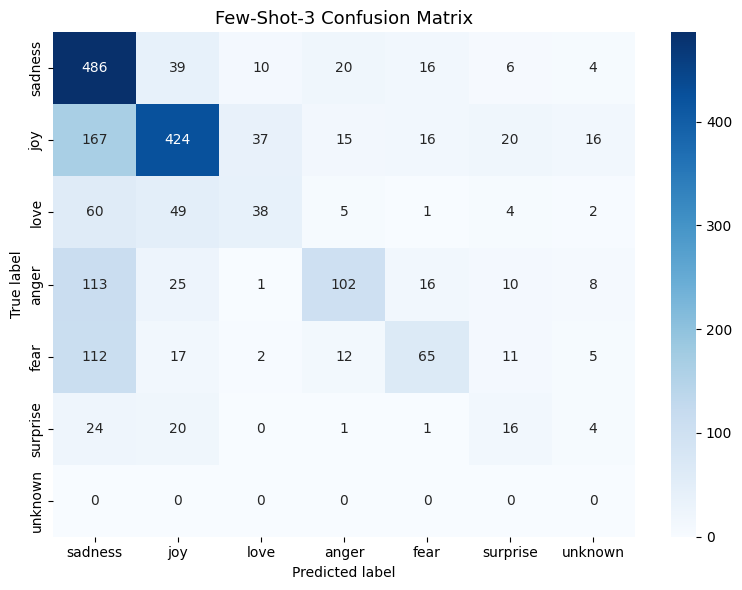

Unparseable outputs counted as wrong: 39/2000


In [27]:
# Evaluate few-shot (3 examples)
print("Running few-shot (3) evaluation...")

fs3_labels, fs3_preds, fs3_time = run_llm_eval(
    fs3_fn,
    dataset["test"],
    sample_size=LLM_EVAL_SIZE,
    setting_name="Few-shot-3"
)

# Unparseable outputs → counted as wrong
fs3_preds_for_metrics = [p if p != -1 else NUM_CLASSES for p in fs3_preds]
n_unknown_fs3 = sum(1 for p in fs3_preds if p == -1)

fs3_acc, fs3_f1 = print_metrics(
    fs3_labels,
    fs3_preds_for_metrics,
    LABEL_NAMES,
    fs3_time,
    "Part 4 — Few-Shot (3)"
)

# Confusion matrix includes unknown predictions instead of hiding them
plot_confusion(
    fs3_labels,
    fs3_preds_for_metrics,
    LABEL_NAMES + ["unknown"],
    "Few-Shot-3 Confusion Matrix"
)

print(f"Unparseable outputs counted as wrong: {n_unknown_fs3}/{len(fs3_preds)}")

In [28]:
fs8_fn = few_shot_prompt(8)

# Show 3 examples for few-shot (8)
show_llm_examples(fs8_fn, "Few-Shot (8) Example Prompts", n=3)

=== Few-Shot (8) Example Prompts ===

Example 1
FULL PROMPT:

You are an emotion classifier.
Classify the following text into exactly one of these emotions:
sadness, joy, love, anger, fear, surprise.

Here are labeled examples:

Text: "i watch her silently feeling dazed from my memory loss"
Emotion: surprise

Text: "i am feeling energetic and healthy for the first time in a long time i guess an almost lb total weightloss will do that for you"
Emotion: joy

Text: "i feared i would feel resentful of her or this process but i dont and i am so happy about that"
Emotion: anger

Text: "i was feeling doubtful and sad about the relationship i have with this man"
Emotion: fear

Text: "im feel alone and i dont know how to cope"
Emotion: sadness

Text: "i have a feeling there are a few more perfect moments coming"
Emotion: joy

Text: "i just had this feeling that i liked him more"
Emotion: love

Text: "i feel if journalists then blamed me"
Emotion: sadness

Now classify this text. Respond with th

Running few-shot (8) evaluation...

Starting Few-shot-8 evaluation on 2000 examples...
Few-shot-8: 100/2000 done | Acc=0.6200 | Macro F1=0.5663 | Unknown=6 | Time=35.9s
Few-shot-8: 200/2000 done | Acc=0.5800 | Macro F1=0.4845 | Unknown=7 | Time=71.5s
Few-shot-8: 300/2000 done | Acc=0.5700 | Macro F1=0.4605 | Unknown=8 | Time=107.1s
Few-shot-8: 400/2000 done | Acc=0.5375 | Macro F1=0.4269 | Unknown=10 | Time=143.3s
Few-shot-8: 500/2000 done | Acc=0.5560 | Macro F1=0.4310 | Unknown=12 | Time=178.4s
Few-shot-8: 600/2000 done | Acc=0.5517 | Macro F1=0.4294 | Unknown=15 | Time=213.5s
Few-shot-8: 700/2000 done | Acc=0.5443 | Macro F1=0.4285 | Unknown=18 | Time=249.2s
Few-shot-8: 800/2000 done | Acc=0.5587 | Macro F1=0.4320 | Unknown=20 | Time=283.9s
Few-shot-8: 900/2000 done | Acc=0.5644 | Macro F1=0.4332 | Unknown=20 | Time=319.0s
Few-shot-8: 1000/2000 done | Acc=0.5680 | Macro F1=0.4373 | Unknown=22 | Time=354.6s
Few-shot-8: 1100/2000 done | Acc=0.5636 | Macro F1=0.4356 | Unknown=22 | Time

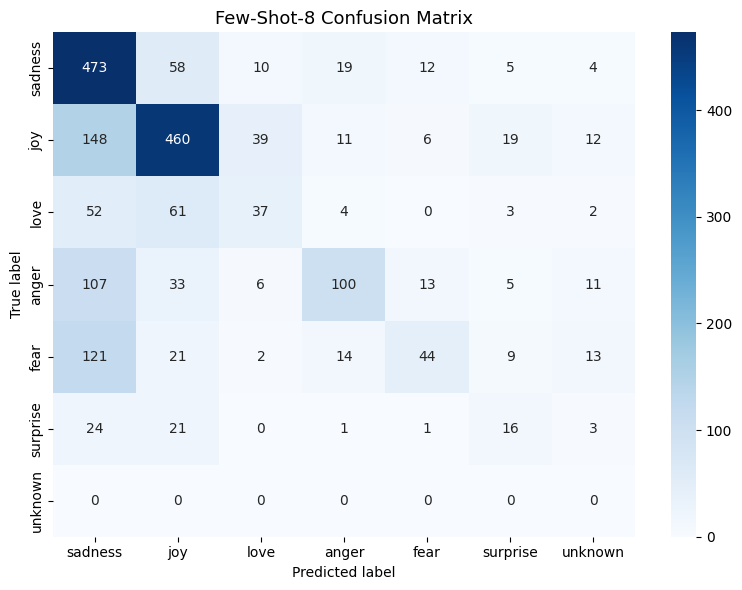

Unparseable outputs counted as wrong: 45/2000


In [29]:
# Evaluate few-shot (8 examples)
print("Running few-shot (8) evaluation...")

fs8_labels, fs8_preds, fs8_time = run_llm_eval(
    fs8_fn,
    dataset["test"],
    sample_size=LLM_EVAL_SIZE,
    setting_name="Few-shot-8"
)

# Unparseable outputs → counted as wrong
fs8_preds_for_metrics = [p if p != -1 else NUM_CLASSES for p in fs8_preds]
n_unknown_fs8 = sum(1 for p in fs8_preds if p == -1)

fs8_acc, fs8_f1 = print_metrics(
    fs8_labels,
    fs8_preds_for_metrics,
    LABEL_NAMES,
    fs8_time,
    "Part 4 — Few-Shot (8)"
)

# Confusion matrix includes unknown predictions instead of hiding them
plot_confusion(
    fs8_labels,
    fs8_preds_for_metrics,
    LABEL_NAMES + ["unknown"],
    "Few-Shot-8 Confusion Matrix"
)

print(f"Unparseable outputs counted as wrong: {n_unknown_fs8}/{len(fs8_preds)}")

In [40]:
# ── CHAIN-OF-THOUGHT prompting ────────────────────────────────────────────
def cot_prompt(text):
    return (
        "You are an emotion classifier. Classify the text into exactly one label: "
        "joy, sadness, anger, fear, love, or surprise.\n\n"
        "Analyze the text in exactly 3 short steps, then give the final label.\n"
        "Use this exact format:\n"
        "Step 1 - Tone: <short answer>\n"
        "Step 2 - Emotion clue: <short answer>\n"
        "Step 3 - Best emotion: <short answer>\n"
        "Final label: <emotion>\n\n"
        f"Text: {text}\n\n"
        "Answer:"
    )

def parse_cot_label(raw_output: str) -> str:
    """Extract label after 'Final label:' in CoT output.
    Uses word-boundary regex (same as parse_label) to avoid partial-word matches.
    """
    lower = raw_output.lower()
    if "final label:" in lower:
        after = lower.split("final label:")[-1].strip()
        for label in LABEL_NAMES:
            if re.search(r'\b' + re.escape(label) + r'\b', after[:50]):
                return label
    return parse_label(raw_output)   # fallback to keyword search

# Show 3 CoT examples
show_llm_examples(
    cot_prompt,
    "Chain-of-Thought Example Prompts",
    n=3,
    parse_fn=parse_cot_label,
    max_new_tokens=120
)


=== Chain-of-Thought Example Prompts ===

Example 1
FULL PROMPT:

You are an emotion classifier. Classify the text into exactly one label: joy, sadness, anger, fear, love, or surprise.

Analyze the text in exactly 3 short steps, then give the final label.
Use this exact format:
Step 1 - Tone: <short answer>
Step 2 - Emotion clue: <short answer>
Step 3 - Best emotion: <short answer>
Final label: <emotion>

Text: im feeling rather rotten so im not very ambitious right now

Answer:

TRUE LABEL: sadness

RAW MODEL OUTPUT:

Step 1 - Tone: The tone of the text is somewhat apathetic and resigned.
Step 2 - Emotion clue: The phrase "feeling rather rotten" indicates a negative emotional state.
Step 3 - Best emotion: Based on the emotion clue, the most fitting emotion is sadness.

Final label: sadness

PARSED LABEL: sadness

Example 2
FULL PROMPT:

You are an emotion classifier. Classify the text into exactly one label: joy, sadness, anger, fear, love, or surprise.

Analyze the text in exactly 3 

Running CoT evaluation...

Starting Chain-of-Thought evaluation on 2000 examples...
Chain-of-Thought: 100/2000 done | Acc=0.5600 | Macro F1=0.4845 | Unknown=0 | Time=709.7s
Chain-of-Thought: 200/2000 done | Acc=0.5350 | Macro F1=0.4218 | Unknown=1 | Time=1418.8s
Chain-of-Thought: 300/2000 done | Acc=0.5533 | Macro F1=0.4292 | Unknown=4 | Time=2128.5s
Chain-of-Thought: 400/2000 done | Acc=0.5350 | Macro F1=0.4057 | Unknown=5 | Time=2843.5s
Chain-of-Thought: 500/2000 done | Acc=0.5360 | Macro F1=0.4005 | Unknown=9 | Time=3566.8s
Chain-of-Thought: 600/2000 done | Acc=0.5317 | Macro F1=0.4033 | Unknown=12 | Time=4314.7s
Chain-of-Thought: 700/2000 done | Acc=0.5314 | Macro F1=0.4025 | Unknown=13 | Time=5016.5s
Chain-of-Thought: 800/2000 done | Acc=0.5375 | Macro F1=0.4109 | Unknown=17 | Time=5738.3s
Chain-of-Thought: 900/2000 done | Acc=0.5400 | Macro F1=0.4092 | Unknown=19 | Time=6456.0s
Chain-of-Thought: 1000/2000 done | Acc=0.5450 | Macro F1=0.4150 | Unknown=19 | Time=7150.0s
Chain-of-Th

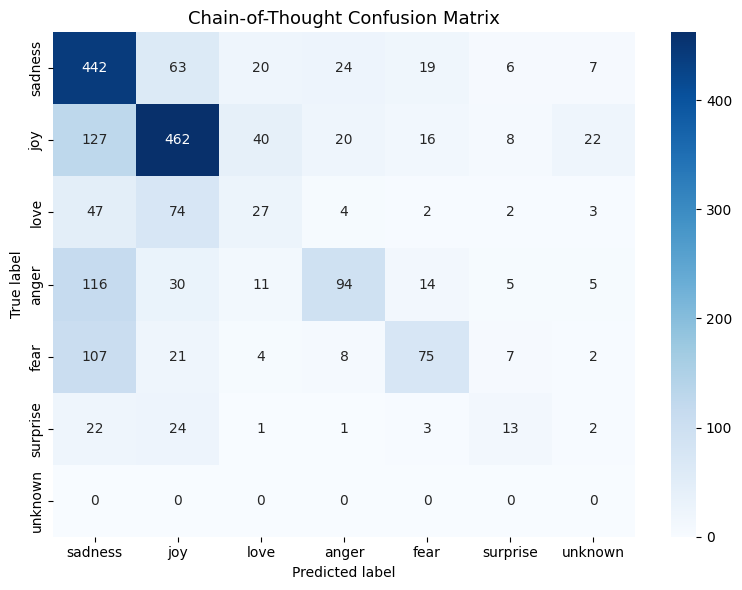

Unparseable outputs counted as wrong: 41/2000


In [41]:
# Evaluate Chain-of-Thought prompting
print("Running CoT evaluation...")

cot_labels, cot_preds, cot_time = run_llm_eval(
    cot_prompt,
    dataset["test"],
    sample_size=LLM_EVAL_SIZE,
    setting_name="Chain-of-Thought",
    parse_fn=parse_cot_label,
    max_new_tokens=120
)

# Unparseable outputs → counted as wrong
cot_preds_for_metrics = [p if p != -1 else NUM_CLASSES for p in cot_preds]
n_unknown_cot = sum(1 for p in cot_preds if p == -1)

cot_acc, cot_f1 = print_metrics(
    cot_labels,
    cot_preds_for_metrics,
    LABEL_NAMES,
    cot_time,
    "Part 4 — Chain-of-Thought"
)

# Confusion matrix includes unknown predictions instead of hiding them
plot_confusion(
    cot_labels,
    cot_preds_for_metrics,
    LABEL_NAMES + ["unknown"],
    "Chain-of-Thought Confusion Matrix"
)

print(f"Unparseable outputs counted as wrong: {n_unknown_cot}/{len(cot_preds)}")

### Part 4 — LLM Prompting Results & Discussion

All four prompting settings were evaluated on the full 2,000-example test set using **Qwen2.5-3B-Instruct** loaded with 4-bit NF4 quantization.

**Summary of all prompting settings:**

| Setting | Accuracy | Macro F1 | Inference Time | Unparseable |
|---------|----------|----------|----------------|-------------|
| Zero-shot | 0.5590 | 0.4439 | 566 s (~9.4 min) | 42 / 2000 |
| Few-shot (3) | **0.5655** | **0.4507** | 603 s (~10 min) | 39 / 2000 |
| Few-shot (8) | 0.5650 | 0.4380 | 705 s (~11.8 min) | 45 / 2000 |
| Chain-of-Thought | 0.5565 | 0.4339 | 14,166 s (~3.9 hr) | 41 / 2000 |

**Key observations:**

- **Best setting: Few-shot (3)** achieved the highest accuracy (0.5655) and Macro F1 (0.4507). Three balanced examples were enough to help the model anchor its output format and calibrate label boundaries.
- **Few-shot (8)** slightly underperforms few-shot (3) on Macro F1 (0.4380 vs 0.4507). More examples in the prompt did not help — likely because the 3B model's context window is used less efficiently with longer prompts, and the examples themselves introduce noise for minority classes.
- **Chain-of-Thought performed worst** (accuracy 0.5565, Macro F1 0.4339), even below zero-shot. Asking Qwen2.5-3B to reason step-by-step before labeling did not improve accuracy — the model's capacity at 3B parameters may be insufficient to benefit from structured reasoning, and the longer generation (up to 120 tokens) introduced more parsing failures and errors. CoT also had by far the highest inference cost: **~3.9 hours** for 2000 examples.
- **Per-class behavior:** All settings struggle most with *love* (F1 ≈ 0.21–0.31) and *fear* (F1 ≈ 0.29–0.42). The model has a strong recall bias toward *sadness* — it tends to classify ambiguous negative text as sadness even when the correct label is anger, fear, or love. *Joy* is the most reliably classified emotion across all settings (F1 ≈ 0.67–0.68).
- **Unparseable outputs** remained low (2–2.25% across settings), confirming that the generation helper and word-boundary regex parser are robust.
- All prompting results fall far below the trained models (LSTM: 0.9285, BERT: 0.9275), showing that for a well-defined closed-label classification task with sufficient training data, prompting a 3B model cannot compete with fine-tuning.


---
## Part 5 — Data Efficiency Experiment (500 examples)

In [42]:
# ── Build balanced 500-example training subset ───────────────────────────
# 500 / 6 = 83 remainder 2
# The 2 extra examples are given to the 2 most frequent classes in the full training set

TARGET_TOTAL = 500
base_count = TARGET_TOTAL // NUM_CLASSES
remainder = TARGET_TOTAL % NUM_CLASSES

train_texts_all  = dataset["train"]["text"]
train_labels_all = dataset["train"]["label"]

full_class_counts = Counter(train_labels_all)
extra_classes = [lbl for lbl, _ in full_class_counts.most_common(remainder)]

target_per_class = {
    lbl: base_count + (1 if lbl in extra_classes else 0)
    for lbl in range(NUM_CLASSES)
}

subset_texts, subset_labels = [], []
per_class_count = Counter()

# Local RNG for reproducible subset selection
rng = random.Random(SEED)
shuffled_idx = list(range(len(train_texts_all)))
rng.shuffle(shuffled_idx)

for idx in shuffled_idx:
    lbl = train_labels_all[idx]

    if per_class_count[lbl] < target_per_class[lbl]:
        subset_texts.append(train_texts_all[idx])
        subset_labels.append(lbl)
        per_class_count[lbl] += 1

    if sum(per_class_count.values()) >= TARGET_TOTAL:
        break

print(f"Total subset size: {len(subset_texts)}")
print("Full training class counts:", dict(full_class_counts))
print("Extra example classes:", extra_classes)
print("Target per-class counts:", target_per_class)
print("Actual subset counts:", dict(per_class_count))

Total subset size: 500
Full training class counts: {0: 4666, 3: 2159, 2: 1304, 5: 572, 4: 1937, 1: 5362}
Extra example classes: [1, 0]
Target per-class counts: {0: 84, 1: 84, 2: 83, 3: 83, 4: 83, 5: 83}
Actual subset counts: {0: 84, 1: 84, 2: 83, 4: 83, 3: 83, 5: 83}


In [43]:
# ── Retrain LSTM on 500-example subset with same training setup ───────────
import copy
import time

# Build a vocabulary ONLY from the 500-example subset
small_vocab = build_vocab(subset_texts, min_freq=2)
small_vocab_size = len(small_vocab)

print(f"Small-data vocabulary size: {small_vocab_size}")

class SmallRNNDataset(Dataset):
    def __init__(self, texts, labels, vocab, max_len=MAX_SEQ_LEN):
        self.encodings = [encode_rnn(t, vocab, max_len) for t in texts]
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return (
            torch.tensor(self.encodings[i], dtype=torch.long),
            torch.tensor(self.labels[i], dtype=torch.long)
        )

# Small-data train set uses small_vocab
small_rnn_train_ds = SmallRNNDataset(subset_texts, subset_labels, small_vocab)

# Validation and test sets must also be encoded using the same small_vocab
small_rnn_val_ds = SmallRNNDataset(
    dataset["validation"]["text"],
    dataset["validation"]["label"],
    small_vocab
)

small_rnn_test_ds = SmallRNNDataset(
    dataset["test"]["text"],
    dataset["test"]["label"],
    small_vocab
)

small_rnn_train_ldr = DataLoader(
    small_rnn_train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True
)

small_rnn_val_ldr = DataLoader(
    small_rnn_val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)

small_rnn_test_ldr = DataLoader(
    small_rnn_test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Re-initialise the model from scratch using the small vocabulary size
small_rnn_model = LSTMClassifier(
    small_vocab_size, EMBED_DIM, HIDDEN_DIM, NUM_LAYERS, NUM_CLASSES
).to(DEVICE)

small_optimizer = torch.optim.Adam(small_rnn_model.parameters(), lr=LR_RNN)

small_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    small_optimizer,
    mode="min",
    patience=2,
    factor=0.5,
    min_lr=1e-5
)

small_best_val_loss = float("inf")
small_best_epoch = 0
small_epochs_without_improvement = 0
small_best_model_state = None

small_rnn_train_losses, small_rnn_val_losses = [], []
small_rnn_train_accs, small_rnn_val_accs = [], []

small_rnn_train_start = time.time()

for epoch in range(1, EPOCHS_RNN + 1):

    # ── Train ──
    small_rnn_model.train()
    running_loss, correct, total = 0.0, 0, 0

    for xb, yb in small_rnn_train_ldr:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)

        small_optimizer.zero_grad()
        logits = small_rnn_model(xb)
        loss = criterion(logits, yb)

        loss.backward()
        nn.utils.clip_grad_norm_(small_rnn_model.parameters(), 1.0)
        small_optimizer.step()

        running_loss += loss.item() * xb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += xb.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # ── Validate using validation set encoded with small_vocab ──
    small_rnn_model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for xb, yb in small_rnn_val_ldr:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)

            logits = small_rnn_model(xb)
            loss = criterion(logits, yb)

            val_loss += loss.item() * xb.size(0)
            val_correct += (logits.argmax(1) == yb).sum().item()
            val_total += xb.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    small_rnn_train_losses.append(train_loss)
    small_rnn_val_losses.append(val_loss)
    small_rnn_train_accs.append(train_acc)
    small_rnn_val_accs.append(val_acc)

    small_scheduler.step(val_loss)
    current_lr = small_optimizer.param_groups[0]["lr"]

    print(f"Epoch {epoch:02d}/{EPOCHS_RNN}  "
          f"train_loss={train_loss:.4f}  train_acc={train_acc:.4f}  "
          f"val_loss={val_loss:.4f}  val_acc={val_acc:.4f}  "
          f"lr={current_lr:.6f}")

    # ── Best model checkpoint ──
    if val_loss < small_best_val_loss:
        small_best_val_loss = val_loss
        small_best_epoch = epoch
        small_best_model_state = copy.deepcopy(small_rnn_model.state_dict())
        small_epochs_without_improvement = 0
    else:
        small_epochs_without_improvement += 1

    # ── Early stopping ──
    if small_epochs_without_improvement >= early_stop_patience:
        print(f"\nEarly stopping triggered at epoch {epoch}.")
        print(f"Best epoch was {small_best_epoch} with val_loss={small_best_val_loss:.4f}.")
        break

# Restore best small-data model
small_rnn_model.load_state_dict(small_best_model_state)

small_rnn_train_time = time.time() - small_rnn_train_start

small_rnn_labels, small_rnn_preds, small_rnn_infer_time = evaluate_model_rnn(
    small_rnn_model,
    small_rnn_test_ldr
)

small_rnn_acc = accuracy_score(small_rnn_labels, small_rnn_preds)
small_rnn_f1 = f1_score(small_rnn_labels, small_rnn_preds, average="macro")

print(f"\nBest small-data LSTM restored from epoch {small_best_epoch}.")
print(f"Total small-data LSTM training time: {small_rnn_train_time:.1f}s ({small_rnn_train_time/60:.2f} min)")
print(f"Small-data LSTM accuracy: {small_rnn_acc:.4f}")
print(f"Small-data LSTM macro F1: {small_rnn_f1:.4f}")

Small-data vocabulary size: 760
Epoch 01/20  train_loss=1.8036  train_acc=0.1700  val_loss=1.7570  val_acc=0.3420  lr=0.001000
Epoch 02/20  train_loss=1.7847  train_acc=0.1900  val_loss=1.8087  val_acc=0.0750  lr=0.001000
Epoch 03/20  train_loss=1.7707  train_acc=0.2340  val_loss=1.8264  val_acc=0.0895  lr=0.001000
Epoch 04/20  train_loss=1.7388  train_acc=0.2760  val_loss=1.7986  val_acc=0.1730  lr=0.000500
Epoch 05/20  train_loss=1.6942  train_acc=0.3200  val_loss=1.8200  val_acc=0.2170  lr=0.000500

Early stopping triggered at epoch 5.
Best epoch was 1 with val_loss=1.7570.

Best small-data LSTM restored from epoch 1.
Total small-data LSTM training time: 3.7s (0.06 min)
Small-data LSTM accuracy: 0.3375
Small-data LSTM macro F1: 0.1025


In [45]:
# ── Re-fine-tune BERT on 500-example subset with same training setup ──────
from datasets import Dataset as HFDataset

bert_small_train_start = time.time()

# Build HF Dataset from the balanced 500-example subset
subset_dict = {"text": subset_texts, "label": subset_labels}

small_hf_ds = HFDataset.from_dict(subset_dict)
small_tok_ds = small_hf_ds.map(tokenize_bert, batched=True)
small_tok_ds = small_tok_ds.rename_column("label", "labels")
small_tok_ds.set_format("torch", columns=["input_ids", "attention_mask", "labels"])

# Fresh BERT model
small_bert_model = AutoModelForSequenceClassification.from_pretrained(
    BERT_MODEL_NAME,
    num_labels=NUM_CLASSES
).to(DEVICE)

small_training_args = TrainingArguments(
    output_dir="./small_bert_output",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    warmup_ratio=0.1,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    logging_strategy="epoch",
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42,
)

small_trainer = Trainer(
    model=small_bert_model,
    args=small_training_args,
    train_dataset=small_tok_ds,
    eval_dataset=tokenized_ds["validation"],
    compute_metrics=compute_metrics,
    data_collator=data_collator,
)

small_trainer.train()

small_bert_train_time = time.time() - bert_small_train_start

small_bert_out = small_trainer.predict(tokenized_ds["test"])
small_bert_preds = np.argmax(small_bert_out.predictions, axis=1)

small_bert_acc = accuracy_score(small_bert_out.label_ids, small_bert_preds)
small_bert_f1 = f1_score(small_bert_out.label_ids, small_bert_preds, average="macro")

print(f"\nSmall-data BERT training time: {small_bert_train_time:.1f}s ({small_bert_train_time/60:.2f} min)")
print(f"Small-data BERT accuracy: {small_bert_acc:.4f}")
print(f"Small-data BERT macro F1: {small_bert_f1:.4f}")

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecated and will b

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,3.606071,3.609411,0.135000,0.105580
2,3.543094,3.551126,0.219000,0.143239
3,3.481843,3.516451,0.221500,0.153373


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La


Small-data BERT training time: 37.5s (0.63 min)
Small-data BERT accuracy: 0.2330
Small-data BERT macro F1: 0.1596


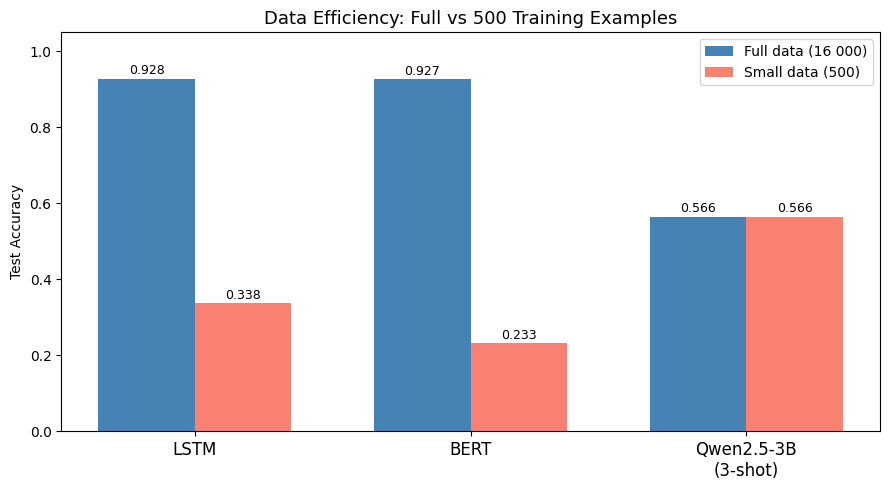

In [46]:

# ── Comparison plot: 500 examples vs full data ───────────────────────────
# Best LLM prompting accuracy is independent of training data
llm_scores = {
    "Zero-shot": zs_acc,
    "3-shot": fs3_acc,
    "8-shot": fs8_acc,
    "CoT": cot_acc
}

best_llm_name = max(llm_scores, key=llm_scores.get)
best_llm_acc  = llm_scores[best_llm_name]

models     = ["LSTM", "BERT", f"Qwen2.5-3B\n({best_llm_name})"]
acc_full   = [rnn_acc,   bert_acc,  best_llm_acc]
acc_small  = [small_rnn_acc, small_bert_acc, best_llm_acc]   # LLM unchanged

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
bars1 = ax.bar(x - width/2, acc_full,  width, label="Full data (16 000)", color="steelblue")
bars2 = ax.bar(x + width/2, acc_small, width, label="Small data (500)",   color="salmon")

ax.set_xticks(x); ax.set_xticklabels(models, fontsize=12)
ax.set_ylabel("Test Accuracy"); ax.set_ylim(0, 1.05)
ax.set_title("Data Efficiency: Full vs 500 Training Examples", fontsize=13)
ax.legend()
for bar in bars1: ax.annotate(f"{bar.get_height():.3f}", xy=(bar.get_x()+bar.get_width()/2, bar.get_height()),
                               xytext=(0,3), textcoords="offset points", ha="center", fontsize=9)
for bar in bars2: ax.annotate(f"{bar.get_height():.3f}", xy=(bar.get_x()+bar.get_width()/2, bar.get_height()),
                               xytext=(0,3), textcoords="offset points", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig("part5_data_efficiency.png", dpi=150, bbox_inches="tight")
plt.show()


### Data Efficiency Discussion

The plot reveals a stark divergence between paradigms — but not in the direction commonly expected. Both trained models collapse dramatically with only 500 examples. The from-scratch LSTM drops from 0.9285 to just 0.3375 accuracy (Macro F1: 0.10): with a vocabulary of only 760 tokens built from 500 texts, it has almost no generalizable word representations. BERT fares even worse on raw accuracy (0.2330) and Macro F1 (0.1596), likely because 500 examples provide too little signal to meaningfully adapt 109M parameters in only 3 epochs — the model essentially fails to fine-tune. The LLM requires no training data at all, which is the ultimate expression of pretraining value: its weights already encode enough linguistic and emotional knowledge to classify directly from prompts, making it the clear winner in the zero-data regime.



---
## Part 6 — Comparative Analysis

In [47]:
# ── Summary table ─────────────────────────────────────────────────────────
summary = {
    "Paradigm": [
    "LSTM (full)", "BERT (full)",
    "Qwen2.5-3B Zero-shot", "Qwen2.5-3B Few-shot (3)",
    "Qwen2.5-3B Few-shot (8)", "Qwen2.5-3B CoT"
    ],
    "Accuracy": [rnn_acc, bert_acc, zs_acc, fs3_acc, fs8_acc, cot_acc],
    "Macro F1": [rnn_f1,  bert_f1,  zs_f1,  fs3_f1,  fs8_f1,  cot_f1],
    "Train Time (s)": [
        round(rnn_train_time, 1), round(bert_train_time, 1),
        "N/A", "N/A", "N/A", "N/A"
    ],
    "Infer Time (s)": [
        round(rnn_infer_time, 2), round(bert_infer_time, 2),
        round(zs_time, 1), round(fs3_time, 1), round(fs8_time, 1), round(cot_time, 1)
    ],
    "Training Data": ["16 000", "16 000", "0", "0", "0", "0"],
}

df_summary = pd.DataFrame(summary)
df_summary["Accuracy"] = df_summary["Accuracy"].apply(lambda x: f"{x:.4f}" if isinstance(x, float) else x)
df_summary["Macro F1"] = df_summary["Macro F1"].apply(lambda x: f"{x:.4f}" if isinstance(x, float) else x)
print(df_summary.to_string(index=False))


               Paradigm Accuracy Macro F1 Train Time (s)  Infer Time (s) Training Data
            LSTM (full)   0.9285   0.8796          130.3            0.49        16 000
            BERT (full)   0.9275   0.8862          411.8            4.63        16 000
   Qwen2.5-3B Zero-shot   0.5590   0.4439            N/A          566.10             0
Qwen2.5-3B Few-shot (3)   0.5655   0.4507            N/A          603.10             0
Qwen2.5-3B Few-shot (8)   0.5650   0.4380            N/A          705.40             0
         Qwen2.5-3B CoT   0.5565   0.4339            N/A        14166.00             0


### Comparative Analysis

#### Test Accuracy & Macro F1
See the summary table above. The LSTM marginally leads on raw accuracy (0.9285 vs 0.9275), while BERT edges ahead on Macro F1 (0.8862 vs 0.8796), reflecting slightly better handling of minority classes. All LLM prompting settings fall far behind both trained models, with Few-Shot (3) achieving the best prompting result (accuracy 0.5655, Macro F1 0.4507). Contrary to common expectation, CoT performs the worst among the four prompting strategies (accuracy 0.5565, Macro F1 0.4339), slightly below zero-shot — the structured reasoning format did not help Qwen2.5-3B on this task.

#### Training Time vs Inference Time
The LSTM trains in 130.3s (just over 2 minutes) and infers in 0.49s — by far the fastest at both stages. BERT fine-tuning took 411.8s (6.9 minutes) on two T4 GPUs, with inference at 4.63s in batch mode. The LLM has zero training cost but is the slowest at inference: zero-shot over 2000 examples took 566s (9.4 minutes), while CoT — which generates up to 120 tokens per example — took 14166s (~3.9 hours) for the same 2000 examples.

#### Data Efficiency
Both trained models collapse with only 500 examples: the LSTM drops to 0.3375 accuracy (Macro F1 0.10), and BERT performs even worse at 0.2330 (Macro F1 0.16) — 500 examples are insufficient to meaningfully fine-tune 109M parameters in 3 epochs. The LLM is entirely unaffected since it requires no training data. The value of pretraining is clearest in the low-data regime, but the benefit goes entirely to prompting-based use rather than fine-tuning on tiny datasets.

#### Failure Modes (from confusion matrices)
- **LSTM:** Weakest on *surprise* (recall 0.62, F1 0.72) and *love* (recall 0.74, F1 0.82). The model lacks contextual depth to distinguish low-frequency minority classes from superficially similar ones.
- **BERT:** Weakest on *love* (F1 0.84) and *surprise* (F1 0.76), where it also shows the largest recall gaps. Deep context resolves most fear/sadness confusion but still struggles with rarer emotion boundaries.
- **LLM (zero-shot):** Worst on *love* (precision 0.30, F1 0.25) and *fear* (recall 0.25, F1 0.37). The model has a strong bias toward *sadness*, which dominates recall across classes. Few-shot examples partially calibrate these boundaries.

#### When to Choose Each Paradigm

**From-Scratch RNN:** Choose when you have a large labelled dataset (>100 k examples), tight latency constraints, no GPU budget for large models, or when the domain is highly specialised and pretrained vocabulary is irrelevant (e.g. protein sequences, proprietary log formats).

**Fine-Tuned Transformer (BERT):** The default choice for nearly all NLP classification tasks when a reasonably sized labelled dataset is available (several thousand examples minimum). It offers the best Macro F1, handles class imbalance better than the LSTM, and inference is fast in batch mode. Ideal for production sentiment, intent, or topic classification.

**LLM Prompting:** Best when you have *no* labelled data or when the task changes frequently (zero retraining cost). The trade-off is very slow inference — CoT at 120 tokens/example is impractical at scale — and lower accuracy than trained models. For this dataset, zero-shot or few-shot (3) offer the best cost-quality trade-off among prompting strategies; CoT added latency without improving accuracy.




In [48]:
print("All parts complete. Key results:")
print(f"  LSTM accuracy       : {rnn_acc:.4f}  |  Macro F1: {rnn_f1:.4f}")
print(f"  BERT accuracy       : {bert_acc:.4f}  |  Macro F1: {bert_f1:.4f}")
print(f"  Zero-shot accuracy  : {zs_acc:.4f}  |  Macro F1: {zs_f1:.4f}")
print(f"  Few-shot-3 accuracy : {fs3_acc:.4f}  |  Macro F1: {fs3_f1:.4f}")
print(f"  Few-shot-8 accuracy : {fs8_acc:.4f}  |  Macro F1: {fs8_f1:.4f}")
print(f"  CoT accuracy        : {cot_acc:.4f}  |  Macro F1: {cot_f1:.4f}")


All parts complete. Key results:
  LSTM accuracy       : 0.9285  |  Macro F1: 0.8796
  BERT accuracy       : 0.9275  |  Macro F1: 0.8862
  Zero-shot accuracy  : 0.5590  |  Macro F1: 0.4439
  Few-shot-3 accuracy : 0.5655  |  Macro F1: 0.4507
  Few-shot-8 accuracy : 0.5650  |  Macro F1: 0.4380
  CoT accuracy        : 0.5565  |  Macro F1: 0.4339
